# Qualité des images

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 1 - Importer et explorer le jeu de données  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Le notebook `01.01` a vérifié que les fichiers sont lisibles et homogènes. Ce notebook regarde le **contenu** des images : y a-t-il des particularités qui pourraient fausser la suite ? Il répond aux questions suivantes :

- Les images ont-elles des particularités (couleur, luminosité, contraste, fond, netteté) ?
- Les sous-ensembles `cancer`, `normal` et `sans_label` se ressemblent-ils ?
- Quelles images sont atypiques, et lesquelles sont inexploitables ?

C'est une exploration : aucune image n'est retirée ici, les décisions de nettoyage sont prises dans le notebook `02.01`. Les données restent **immuables** dans `data/raw/`.

## 1. Chargement

L'inventaire des images brutes provient de `brain_mri.dataset`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from brain_mri.config import FIGURES_DIR, RAW_DATA_DIR
from brain_mri.dataset import build_inventory
from brain_mri.quality import DESCRIPTOR_COLUMNS, describe_images

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

images = build_inventory(RAW_DATA_DIR)
print(f"{len(images):,} images, dont {images['is_labeled'].sum():,} annotées.")
display(images.groupby("subset").size().rename("images").to_frame())

1,506 images, dont 100 annotées.


,images
subset,
cancer,50
normal,50
sans_label,1406


## 2. Descripteurs

On calcule cinq descripteurs simples par image :

- `brightness` : luminosité moyenne (0 à 255) ;
- `contrast` : écart-type des niveaux de gris ;
- `background_fraction` : part des pixels quasi noirs (niveau de gris inférieur à 10) ;
- `channel_gap` : écart maximal entre canaux RGB. Les IRM en niveaux de gris ont un écart nul ou presque ;
- `sharpness` : netteté, variance du laplacien des niveaux de gris en pleine résolution. Plus la valeur est grande, plus les contours sont marqués.

In [2]:
images = pd.concat([images, describe_images(images["filepath"])], axis=1)

display(images[DESCRIPTOR_COLUMNS].describe().round(2))
display(
    images.groupby("subset")["is_color"]
    .agg(images_en_couleur="sum", images="count")
    .reset_index()
)

,brightness,contrast,background_fraction,channel_gap,sharpness
count,1506.00,1506.00,1506.00,1506.00,1506.00
mean,52.40,48.94,0.36,0.20,120.13
std,17.38,13.71,0.14,3.25,357.25
min,14.95,20.89,0.00,0.00,8.27
25%,41.29,39.91,0.28,0.00,38.20
50%,50.26,45.03,0.36,0.00,54.76
75%,59.25,54.31,0.44,0.00,79.78
max,136.22,119.18,0.76,81.00,5745.80


,subset,images_en_couleur,images
0,cancer,0,50
1,normal,1,50
2,sans_label,9,1406


### Les sous-ensembles se ressemblent-ils ?

Si les images `cancer` et `normal` différaient systématiquement par leur luminosité, leur fond ou leur netteté, un modèle pourrait apprendre ces indices plutôt que la pathologie. On compare aussi les images annotées aux images non annotées : l'hypothèse semi-supervisée suppose qu'elles proviennent de la même distribution.

,brightness,contrast,background_fraction,sharpness
subset,,,,
cancer,43.58,42.75,0.39,54.35
normal,55.34,56.13,0.36,115.23
sans_label,50.23,44.87,0.36,54.18


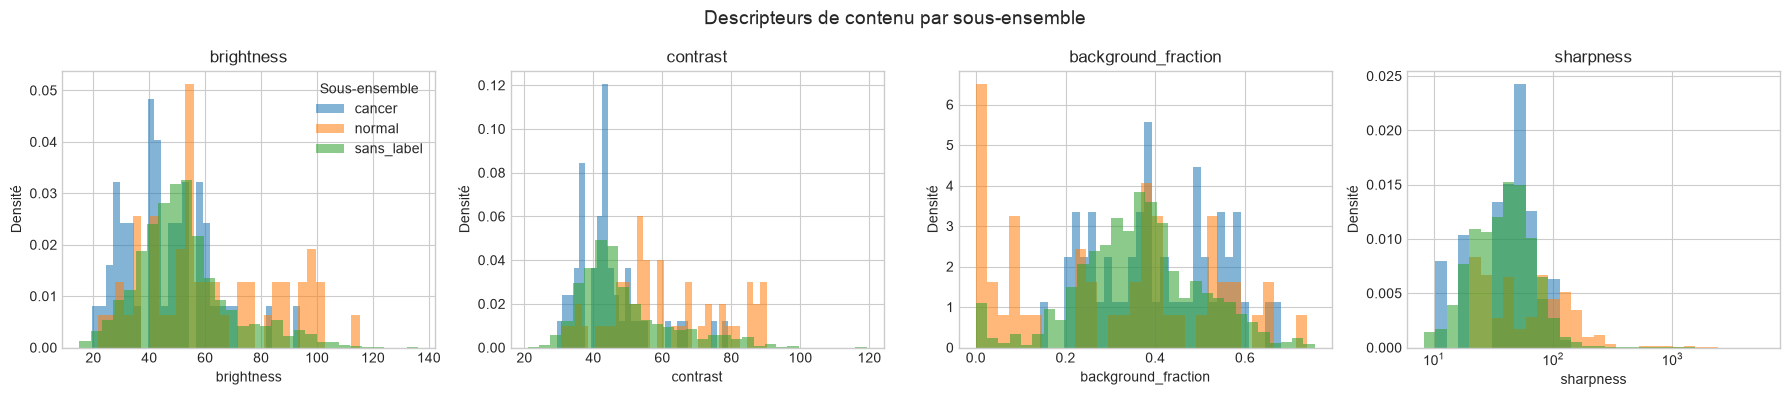

In [3]:
descriptor_columns = [
    "brightness",
    "contrast",
    "background_fraction",
    "sharpness",
]

display(images.groupby("subset")[descriptor_columns].median().round(2))

figure, axes = plt.subplots(1, 4, figsize=(18, 4))
for axis, column in zip(axes, descriptor_columns, strict=True):
    bins = (
        np.geomspace(images[column].min(), images[column].max(), 31)
        if column == "sharpness"
        else 30
    )
    for subset, group in images.groupby("subset"):
        axis.hist(
            group[column],
            bins=bins,
            alpha=0.55,
            density=True,
            label=subset,
        )
    axis.set(title=column, xlabel=column, ylabel="Densité")
    if column == "sharpness":
        axis.set_xscale("log")
axes[0].legend(title="Sous-ensemble")
figure.suptitle("Descripteurs de contenu par sous-ensemble", fontsize=14)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "descripteurs-images.png", dpi=120, bbox_inches="tight"
)
plt.show()

### Images atypiques

On affiche les images aux valeurs extrêmes : les images en couleur, les plus sombres, les plus lumineuses, celles avec le plus de fond et les moins nettes.

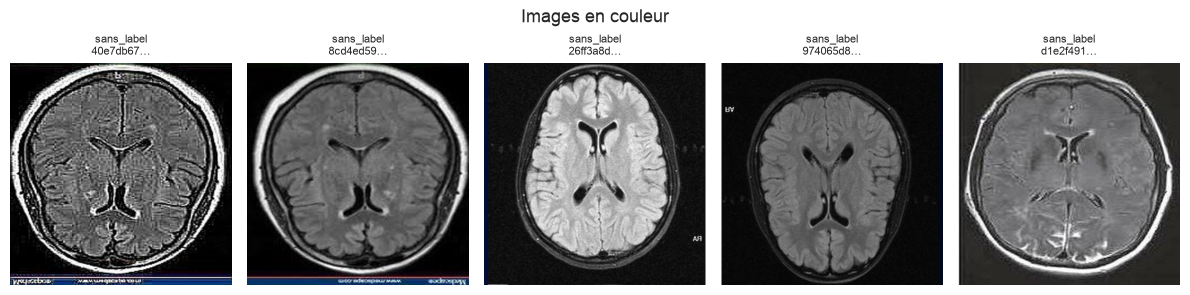

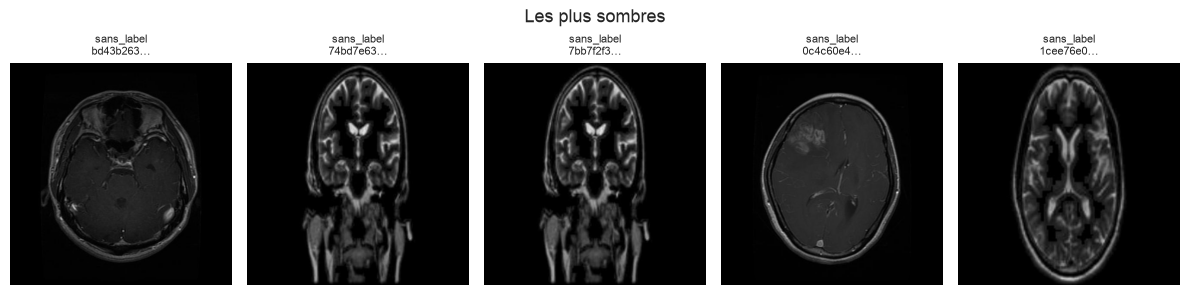

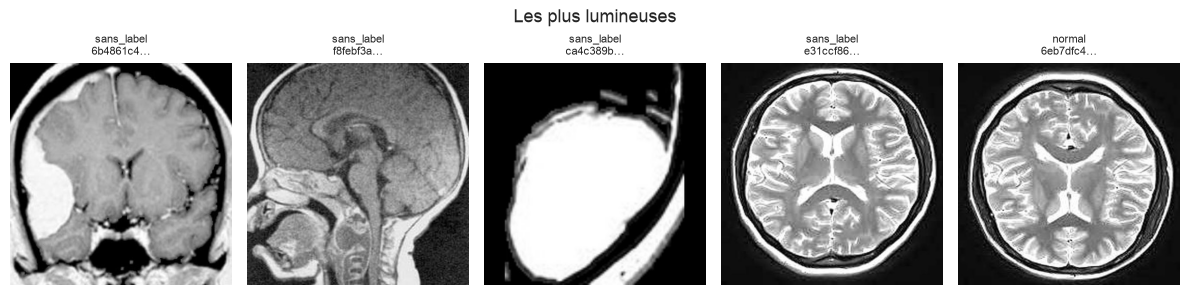

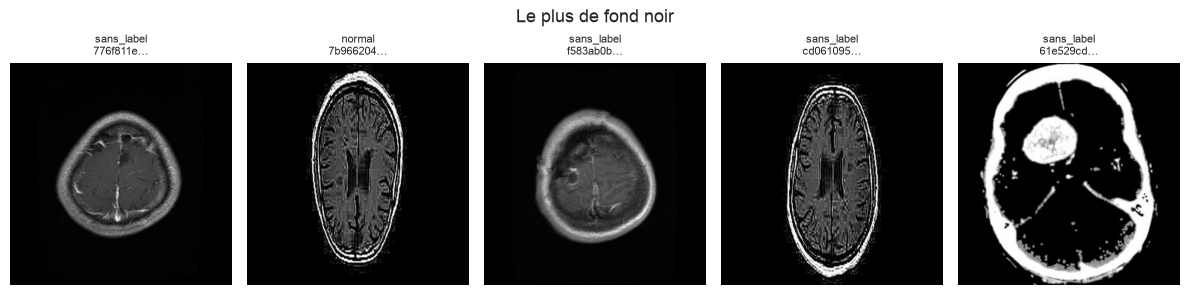

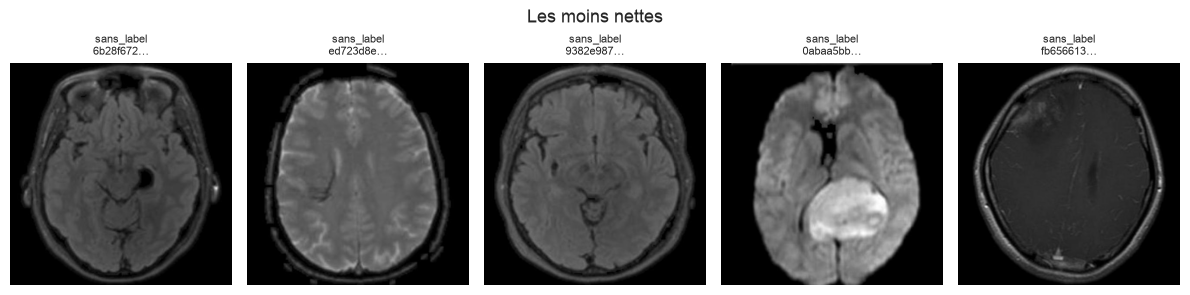

Images en couleur annotées : 1


In [4]:
N_ATYPICAL = 5

atypical_groups = {
    "couleur": (
        "Images en couleur",
        images.nlargest(N_ATYPICAL, "channel_gap"),
    ),
    "sombres": (
        "Les plus sombres",
        images.nsmallest(N_ATYPICAL, "brightness"),
    ),
    "lumineuses": (
        "Les plus lumineuses",
        images.nlargest(N_ATYPICAL, "brightness"),
    ),
    "fond": (
        "Le plus de fond noir",
        images.nlargest(N_ATYPICAL, "background_fraction"),
    ),
    "floues": (
        "Les moins nettes",
        images.nsmallest(N_ATYPICAL, "sharpness"),
    ),
}

for slug, (title, group) in atypical_groups.items():
    figure, axes = plt.subplots(1, N_ATYPICAL, figsize=(2.4 * N_ATYPICAL, 3.1))
    for axis, (_, row) in zip(axes, group.iterrows(), strict=True):
        with Image.open(row["filepath"]) as image:
            axis.imshow(image)
        axis.set_title(f"{row['subset']}\n{row['image_id'][:8]}…", fontsize=8)
        axis.axis("off")
    figure.suptitle(title, fontsize=13)
    plt.tight_layout()
    figure.savefig(
        FIGURES_DIR / f"images-atypiques-{slug}.png",
        dpi=120,
        bbox_inches="tight",
    )
    plt.show()

print(
    "Images en couleur annotées :",
    images.loc[images["is_color"], "is_labeled"].sum(),
)

### Image inexploitable

Parmi les images les plus lumineuses, une est **inexploitable** : une tache blanche saturée, avec des artefacts visuels et aucun détail anatomique. Elle a aussi le **contraste le plus élevé** du jeu. Ses caractéristiques ne seraient que du bruit pour un modèle. Toutes les autres images atypiques sont de vraies IRM lisibles.

ca4c389b-8e9b-40d0-b149-1c81934ea251 (sans_label) : luminosité 116.4, contraste 119.2.


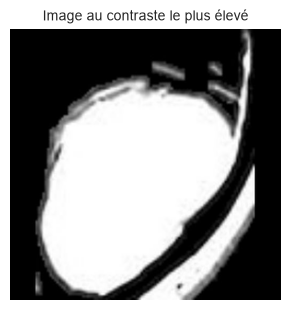

In [5]:
saturated = images.nlargest(1, "contrast").iloc[0]
print(
    f"{saturated['image_id']} ({saturated['subset']}) : "
    f"luminosité {saturated['brightness']:.1f}, "
    f"contraste {saturated['contrast']:.1f}."
)

figure, axis = plt.subplots(figsize=(3.5, 3.7))
with Image.open(saturated["filepath"]) as image:
    axis.imshow(image)
axis.set_title("Image au contraste le plus élevé", fontsize=10)
axis.axis("off")
plt.show()

## Conclusion de l'analyse

### Synthèse

- **Jeu brut** : 1 506 images, dont 100 annotées (50 `cancer`, 50 `normal`) et 1 406 non annotées.
- **Les deux classes annotées diffèrent par leur contenu.** Les images `cancer` sont plus sombres (luminosité médiane de 43,6 contre 55,3) et moins contrastées (42,8 contre 56,1) que les images `normal`, et **deux fois moins nettes** (netteté médiane de 54,4 contre 115,2). La part de fond est voisine (0,39 contre 0,36). Un modèle pourrait apprendre ces indices à la place de la pathologie.
- **Les images non annotées se situent entre les deux classes** pour la luminosité (50,2) et le contraste (44,9, plus proche des `cancer`). Elles ont la netteté des `cancer` (54,2).
- **10 images sont en couleur** (1 `normal` annotée, 9 non annotées).
- **Une image est inexploitable** : une tache blanche saturée, non annotée, au contraste le plus élevé du jeu (écart-type de 119). Les autres images atypiques sont de vraies IRM lisibles.

### Suite

Aucune image n'est retirée dans ce notebook. L'exclusion de l'image saturée est décidée dans le notebook `02.01`. Les écarts de luminosité, de contraste et de netteté entre les classes sont à garder en tête pour le prétraitement et pour l'interprétation des résultats.

### Limites

- Ces écarts peuvent venir de différences de source d'acquisition (appareil, protocole) plutôt que de la pathologie. Sans métadonnées, on ne peut pas le vérifier.
- Les descripteurs sont des mesures globales simples : ils ne remplacent pas une lecture par un radiologue.